<a href="https://colab.research.google.com/github/EstelleYang111/MSSP607/blob/main/WeeklyModules/Week10/Participation_Activity_Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Week 10: Improved Flickr Image Downloader
# Improvements: reuse one connection, verify image content, and handle download errors.

import requests
from pathlib import Path
import time

category = "cats"
download_folder = Path(f"flickr_{category}")
download_folder.mkdir(exist_ok=True)

feed_url = "https://www.flickr.com/services/feeds/photos_public.gne"
params = {
    "tags": category,
    "format": "json",
    "nojsoncallback": 1
}

# Reuse the same session for the feed and image downloads.
with requests.Session() as session:
    try:
        response = session.get(feed_url, params=params, timeout=30)
        response.raise_for_status()
        photos = response.json().get("items", [])
    except (requests.RequestException, ValueError) as error:
        raise RuntimeError(f"Could not load the Flickr photo feed: {error}") from error

    print(f"Category: {category}")
    print(f"Photos found in the public feed: {len(photos)}")

    downloaded_files = []
    failed = 0

    for index, photo in enumerate(photos, start=1):
        image_url = photo.get("media", {}).get("m")
        if not image_url:
            failed += 1
            print(f"Skipped photo {index}: no image URL")
            continue

        try:
            image_response = session.get(image_url, timeout=30)
            image_response.raise_for_status()

            # An error page should not be saved as a JPEG image.
            content_type = image_response.headers.get("Content-Type", "").lower()
            if not content_type.startswith("image/"):
                failed += 1
                print(f"Skipped photo {index}: response was not an image")
                continue

            filename = download_folder / f"image_{index:03d}.jpg"
            filename.write_bytes(image_response.content)
            downloaded_files.append(filename)
            print(f"Downloaded: {filename}")

            time.sleep(0.5)

        except (requests.RequestException, OSError) as error:
            failed += 1
            print(f"Failed to download photo {index}: {error}")

print(f"\nSuccessfully downloaded this run: {len(downloaded_files)}")
print(f"Failed or skipped: {failed}")
print(f"Saved in: {download_folder.resolve()}")


Category: cats
Photos found in the public feed: 20
Downloaded: flickr_cats/image_001.jpg
Downloaded: flickr_cats/image_002.jpg
Downloaded: flickr_cats/image_003.jpg
Downloaded: flickr_cats/image_004.jpg
Downloaded: flickr_cats/image_005.jpg
Downloaded: flickr_cats/image_006.jpg
Downloaded: flickr_cats/image_007.jpg
Downloaded: flickr_cats/image_008.jpg
Downloaded: flickr_cats/image_009.jpg
Downloaded: flickr_cats/image_010.jpg
Downloaded: flickr_cats/image_011.jpg
Downloaded: flickr_cats/image_012.jpg
Downloaded: flickr_cats/image_013.jpg
Downloaded: flickr_cats/image_014.jpg
Downloaded: flickr_cats/image_015.jpg
Downloaded: flickr_cats/image_016.jpg
Downloaded: flickr_cats/image_017.jpg
Downloaded: flickr_cats/image_018.jpg
Downloaded: flickr_cats/image_019.jpg
Downloaded: flickr_cats/image_020.jpg

Successfully downloaded this run: 20
Failed or skipped: 0
Saved in: /content/flickr_cats


Images available to preview: 20


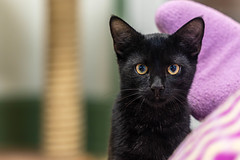

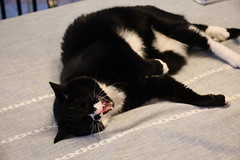

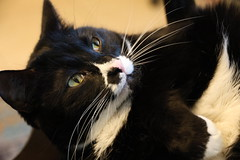

In [2]:
# Display up to three images downloaded in this run.
from IPython.display import display, Image

print(f"Images available to preview: {len(downloaded_files)}")
for image_file in downloaded_files[:3]:
    display(Image(filename=str(image_file), width=300))